In [3]:
import numpy as np
from tqdm import tqdm


## Implementando una NN desde cero

Ya llevo un año sin haber terminado este proyecto. Vamos a cerrar este loop esta semana! No creo que me falte tanto. Vamos a volver a leer nielsen y a tratar de escribir la red neuronal bajo mis decisiones de arquitectura. La idea es tener todos los cálculos en la cabeza y traducirlos a código. Esto lo hago para aprender, entonces lo mejor será no depender de la asistencia de la IA. 

In [4]:
def sigmoid(z):
    '''
    Activation Function
    '''
    return 1/(1 + np.exp(-z))

def del_sigmoid(z):
    ''' 
    Derivative of the activation function 
    '''
    phi = sigmoid(z)
    return phi * (1 - phi) 



# Single Layer
We'll start by implementing a NN with a single layer. 

In [5]:
W = np.random.uniform(0, 1, (3, 4)) # (n_out, n_in)
print(W)
print(W.shape)
 

[[0.85058154 0.96694892 0.54487609 0.92539667]
 [0.01764774 0.87818331 0.8757232  0.66593336]
 [0.99251185 0.50815303 0.40482233 0.93633136]]
(3, 4)


In [6]:
class layer:

    def __init__(self, n_in, n_out) -> None:
        ''' 
        Initialize layer with a random weight matrix and a random bias
        '''

        self.W = np.random.uniform(-1, 1, (n_out, n_in)) # (n_out, n_in)
        self.phi = sigmoid
        self.del_phi = del_sigmoid
        self.b = np.random.uniform(-1, 1, (n_out, 1)) # (n_out, 1)

        pass

    def __call__(self, x):
        ''' 
        Forward pass of the neural network layer. 
        NN(x) = phi(Wx + b)
        x is an array of the shape (n_in, d)
        '''
        Wx = self.W @ x
        arg = Wx + self.b
        return self.phi(arg), arg # (n_out)

    def loss(self, data):
        ''' 
        Loss function. With respect to any set of data
        '''
        # retrieve datapoints
        x = data[0] # (n_in, d)
        y = data[1] # (n_out, d)
        d = x.shape[1]
        dp = y.shape[1]
        assert d == dp, 'data shapes of x and y dont match'

        # In and output vector dimensions
        n_in = x.shape[0]
        n_out = y.shape[0]

        # Forward pass and residuals (n_out, d)
        C, arg = self(x)
        res = y - C 

        # Compute magnitude squared of each residual
        mags = np.linalg.norm(res, axis=0) ** 2 # (d,) 
        assert mags.shape[0] == d

        # Return mean magnitude squared 
        return 0.5 * np.mean(mags)


    def grad_loss(self, data):
        '''
        Gradient of the loss function as I've computed it. 
        Requires data as a tuple (x, y) where x is an array of the form (n_in, d),
        and y is an array of shape (n_out, d). 
        d is the number of data points in the dataset.

        Returns a vector del_b of shape (n_out,) and a matrix del_W of shape (n_out, n_in)  
        '''
        x = data[0] # (n_in, d)
        y = data[1] # (n_out, d)
        d = x.shape[1]
        dp = y.shape[1]
        assert d == dp, 'data shapes of x and y dont match'
        n_in = x.shape[0]
        n_out = y.shape[0]

        # Forward pass, residuals and component-wise multiplication (n_out, d)
        C, arg = self(x)
        res = y - C 
        phi_derivative = self.del_phi(arg)
        mult = res * phi_derivative  

        # Summation over mult and averaging. I guess this is the most computationally-intensive part.  
        del_b = - np.reshape(np.mean(mult, axis=1), (-1,1)) # (n_out, 1)
        del_W = -1 / d * np.einsum('ij,kj -> ik', mult, x) # (n_out, n_in) 

        return del_W, del_b
    
    def jacobian(self, x):
        ''' 
        Jacobian of the layer. This is the total derivative of the layer with respect to its input x. Not its parameters
        From our calculations, J(x) = diag(phi'(Wx + b)) W 

        If we want to compute the full jacobian with respect to all inputs in the dataset, we can try to return an array of shape
        (n_out, n_in, d)
        '''

        # Compute layer's argument and output 
        C, arg = self(x) # (n_out, d). Make sure x always has this shape
        W = self.W.copy()
        n_in = x.shape[0]
        n_out = C.shape[0]
        d = x.shape[1]

        # Compute Activation Derivatives 
        phi_derivative = self.del_phi(arg) # (n_out, d)

        # Reshape arrays for multiplication
        W = np.reshape(W, (n_out, n_in, 1))
        phi_derivative = np.reshape(phi_derivative, (n_out, 1, d))

        # Compute Jacobian
        J = phi_derivative * W # (n_out, n_in, d)

        # Assertion for correct shape
        assert J.shape == (n_out, n_in, d) 

        return J




Test of the forward pass and layer derivative with a simple example. General Nebengedanken. 

In [13]:
L = layer(2, 2)

Wo = L.W
bo = L.b

print('initial weights', Wo)
print('initial bias', bo)

# Test shapes
L.W = np.array([[1, -1],
                [-1, 1]])
assert Wo.shape == L.W.shape, 'weight type wrong'

L.b = np.array([[0], 
                [0]]) 
assert bo.shape == L.b.shape, 'bias type wrong'

#L.b = L.b.reshape((2,))
#L.b = L.b.reshape((-1,1))
print('shape L.b', L.b.shape)

# Test Input (2, 3)
x = np.array([[1, 10000, -100000], 
              [1, 1000, 100000]])
            

res, _ = L(x)
print(res)
assert res[0,0] == 0.5, 'wrong NN layer forward pass'

x = np.array([[1], 
              [1]])
            

J = L.jacobian(x)
print('shape Jacobian', J.shape) # (2, 2, 3)
print('Jacobian at [1,1]^T', J[:,:,0])

# New Layer!

L2 = layer(2, 4)

# (2, 3)
x = np.array([[1, 2, 3], 
              [1, 4, 1]])

# (4, 3)
y = np.array([[1, 2, 3], 
              [1, 4, 1],
              [2, 2, 2],
              [1, 0, 1]])

# I want to find tens such that tens[i] = y[i] @ x[i]^T. Thus, tens must have a shape of [d, n_out, n_in]

tens1 = np.tensordot(y, x.T, axes=0)
#print('shape tens1', tens1.shape) # want (3, 4, 2)
#print('tens1', tens1)

tens2 = np.einsum('ij,kj -> ik', y, x)

print('shape tens2', tens2.shape) # want (4, 2)
print('tens2', tens2)

tens2 = np.einsum('ij,kj -> jk', y, x)

print('mean over 0th axis', np.mean(x, axis=0), np.mean(x, axis=0).shape) # (3,), [1, 3, 2]
print('mean over 1st axis', np.mean(x, axis=1), np.mean(x, axis=1).shape) # (2,), [2, 2]

data = (x, y)

print('L2(x)', L2(x)[0])

grad_W, grad_b = L2.grad_loss(data) 
print('shape of grad_W', grad_W.shape) # (4, 2)
print('shape of grad_b', grad_b.shape) # (4, 1)

assert grad_W.shape == (4,2)
assert grad_b.shape == (4,1)

print(np.arange(3))

loss = L2.loss(data)
print('shape of loss', loss.shape) # () just a number
print('loss', loss)


initial weights [[ 0.82790028  0.13009083]
 [-0.78915616 -0.65439777]]
initial bias [[-0.13217541]
 [ 0.63429267]]
shape L.b (2, 1)
[[0.5 1.  0. ]
 [0.5 0.  1. ]]
shape Jacobian (2, 2, 1)
Jacobian at [1,1]^T [[ 0.10499359 -0.10499359]
 [-0.10499359  0.10499359]]
shape tens2 (4, 2)
tens2 [[14 12]
 [12 18]
 [12 12]
 [ 4  2]]
mean over 0th axis [1. 3. 2.] (3,)
mean over 1st axis [2. 2.] (2,)
L2(x) [[0.60539358 0.91259495 0.7421662 ]
 [0.84885944 0.99172067 0.93657932]
 [0.13722075 0.03157216 0.03496137]
 [0.31263533 0.52057478 0.09307282]]
shape of grad_W (4, 2)
shape of grad_b (4, 1)
[0 1 2]
shape of loss ()
loss 4.714100727336569


/var/folders/w4/vfd0d95d1xb2fb8hjqgnskzc0000gn/T/ipykernel_1035/3776549370.py:5: RuntimeWarning: overflow encountered in exp
  return 1/(1 + np.exp(-z))


Tests seem alright. I can no go and define a training function! 

In [98]:
def test_train_split(data, split):
    ''' 
    Divides the data in test and training sets according to the split. 
    split is a number between 0 and 100 defining the percentage of training data.
    '''
    x = data[0]
    y = data[1]
    d = x.shape[1]
    idxs = np.arange(d)

    # number of training samples
    n_train = round(d * split / 100) 

    # sample indices for training set 
    np.random.seed(seed=42)
    idxs_train = np.random.randint(0, d, n_train)

    # remaining indices belong to the test set   
    idxs_test = np.array([])
    for i in range(d):
        if i not in idxs_train:
            np.append(idxs_test, i)

    # Training Set
    x_train = x[idxs_train]
    y_train = y[idxs_train]

    # Test Set
    x_test = x[idxs_test]
    y_test = y[idxs_test]

    # Consistency test
    assert x_test.shape[0] + x_train.shape[0] == x.shape[0]
    assert y_test.shape[0] + y_train.shape[0] == y.shape[0]

    return (x_train, y_train), (x_test, y_test)



def train(L, train_data, val_data, epochs=20, minibatch_size=50, eta=0.1, verbose=True):
    '''
    Training function for a single layer using SGD. Must include a test/train split. 

    - L is a layer as defined above. Initial weights and biases already initialized.
    - training_data is 
    - epochs is the number of times that the training loop will visit the full training set 
    - minibatch_size is the size of the minibatch. *Same batching every epoch* TO DO: randomize batches
    - eta is the learning rate

    '''
    # Compute initial training loss
    loss0 = L.loss(train_data)
    train_losses = np.zeros(epochs)
    val_losses = np.zeros(epochs)
    print('Initial Training Loss', loss0)


    x_train = train_data[0]
    y_train = train_data[1]

    x_val = val_data[0]
    y_val = val_data[1]

    # Compute number of minibatches
    d_train = x_train.shape[1]
    n_batches = int(d_train / minibatch_size)
    
    for e in tqdm(range(epochs)):

        for n in range(n_batches):

            # Organize batch's training samples for SGD
            # Edge case: last batch may not be big enough. Avoid slicing error
            if n == n_batches - 1:
                x_batch = x_train[:, n * minibatch_size :]
                y_batch = y_train[:, n * minibatch_size :]
            else:
                x_batch = x_train[:, n * minibatch_size : (n+1) * minibatch_size]
                y_batch = y_train[:, n * minibatch_size: (n+1) * minibatch_size]

            data_batch = (x_batch, y_batch)

            # Compute gradients   
            del_W, del_b = L.grad_loss(data_batch)

            # Apply gradient step to weights and biases
            L.W = L.W - eta * del_W
            L.b = L.b - eta * del_b

        # Recompute loss at the end of the epoch
        loss = L.loss(train_data)
        val_loss = L.loss(val_data)
        train_losses[e] = loss
        val_losses[e] = val_loss

        if verbose==True:
            print('Loss at epoch e =', e, ':', loss)

    return L, train_losses, val_losses



Now we can write a couple of cute little plots to visualize the training loss as a function of the epoch

In [88]:
import matplotlib.pyplot as plt 

def plot_loss(train_losses, val_losses):
    epochs = range(len(train_losses))
    plt.figure()
    plt.plot(epochs, train_losses, label='training loss')
    plt.plot(epochs, val_losses, label='validation loss')
    plt.grid(True)
    plt.legend(loc='best')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.show()



Lastly, we may now try to learn the MNIST dataset! With a single layer, there is going to be massive compression and I don't expect the network to perform well. However, it will be informative to see the speed at which the training run can go and whether the loss actually decreases with the epoch. Later we will adapt the training functions for NNs with more than one layer. I don't know if this is going to be trivial at all. 

Start by interacting with the dataset! how can I open the pkl file? The goal of this bit is to get x and y in appropriate shapes for them to be fed into the training run!

(50000, 784) (50000,)


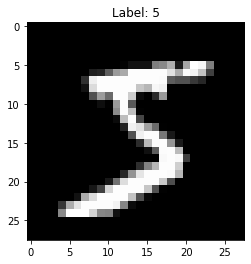

In [69]:
import pickle
import gzip

with gzip.open('neural-networks-and-deep-learning-master/data/mnist.pkl.gz', 'rb') as f:
    training_data, validation_data, test_data = pickle.load(f, encoding='latin1')

print(training_data[0].shape, training_data[1].shape)   # (50000, 784) (50000,)

first_image = training_data[0][0]
first_label = training_data[1][0]

# Reshape the first image to 28x28 pixels
image = first_image.reshape(28, 28)

# Display the image
plt.imshow(image, cmap='gray')
plt.title(f"Label: {first_label}")
plt.show()


The data is already vectorized. Now, we only need to change the labels into one-hot encondings

In [92]:
# Extract labels and training images from training_data
y_labels = training_data[1]
x_train = training_data[0].T

# Extract validation data
y_labels_val = validation_data[1]
x_val = validation_data[0].T

print(x_train.shape) # (728, 50000)
d = len(y_labels)

def labels_to_onehot(labels):
    '''
    Produces one-hot encodings of a set of labels
    '''
    d_size = len(labels)
    one_hot = np.zeros((10, d_size))

    # Fill up one-hot encodings
    for n in range(d_size):
        one_hot[labels[n], n] = 1

    return one_hot

def onehot_to_labels(onehot):
    '''
    Produces labels from one-hot encodings
    '''
    d_size = onehot.shape[1]
    labels = np.zeros(d_size)

    # Fill up labels
    for n in range(d_size):
        labels[n] = np.argmax(onehot[:,n])

    return labels


y_train = labels_to_onehot(y_labels)
y_val = labels_to_onehot(y_labels_val)

# Organize training data
train_data = (x_train, y_train)
val_data = (x_val, y_val)

(784, 50000)


Test training run!

Initial Training Loss 2.341495047520227


100%|██████████| 30/30 [00:32<00:00,  1.08s/it]


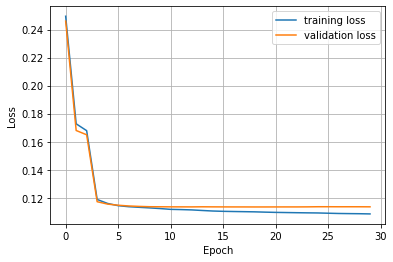

In [104]:
L = layer(784, 10)

L, train_losses, val_losses = train(L, train_data, val_data, epochs=30, minibatch_size=50, eta=10, verbose=False)

plot_loss(train_losses, val_losses)

Let's see how the network performs. We will define the accuracy metric: out of all examples, how many can it characterize well?

In [105]:
# Extract test set 
x_test = test_data[0].T
y_test = test_data[1]

# Compute predicted labels on the test set
pred_onehot, _ = L(x_test)
pred_labels = onehot_to_labels(pred_onehot)

def compute_accuracy(L, x, true_labels):

    pred_onehot, _ = L(x)
    pred_labels = onehot_to_labels(pred_onehot)

    accuracy = np.mean(true_labels == pred_labels)
    return accuracy


print('labels shape', pred_labels.shape)

accuracy = np.mean(y_test == pred_labels)
print('accuracy on the test set', accuracy)

accuracy = compute_accuracy(L, x_test, y_test)
print(accuracy)


labels shape (10000,)
accuracy on the test set 0.8393
0.8393


An accuracy of 0.912 is higher than I expected for this simple network of only a single layer and a huge bottleneck. Before scaling, let's do some hyperparameter experiments.

Initial Training Loss 1.8363630799305888


100%|██████████| 30/30 [00:30<00:00,  1.03s/it]


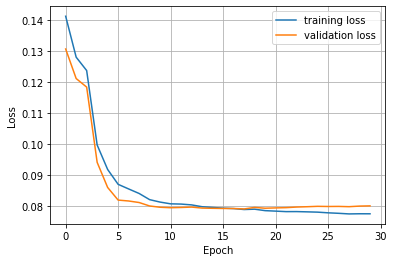

accuracy for lr = 10 : 0.9218
Initial Training Loss 1.8363630799305888


100%|██████████| 30/30 [00:31<00:00,  1.06s/it]


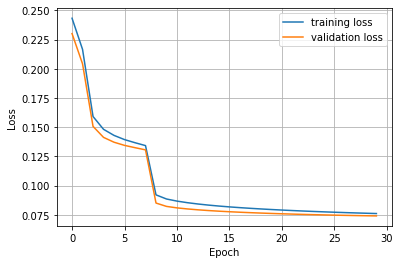

accuracy for lr = 1 : 0.9241
Initial Training Loss 1.8363630799305888


100%|██████████| 30/30 [00:31<00:00,  1.05s/it]


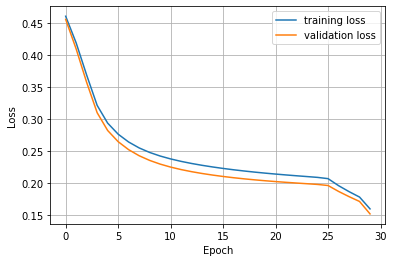

accuracy for lr = 0.1 : 0.8022
Initial Training Loss 1.8363630799305888


100%|██████████| 30/30 [00:31<00:00,  1.04s/it]


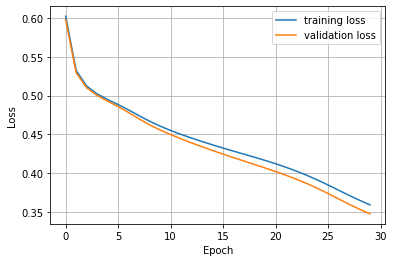

accuracy for lr = 0.01 : 0.4921
Initial Training Loss 1.8363630799305888


100%|██████████| 30/30 [00:30<00:00,  1.02s/it]


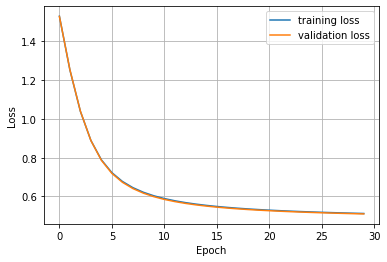

accuracy for lr = 0.001 : 0.2001
[0.9218 0.9241 0.8022 0.4921 0.2001]


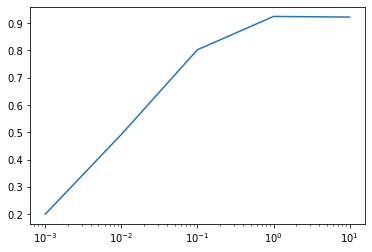

In [101]:
import copy
epochs = 50
etas = [10, 1, 0.1, 0.01, 0.001]
accuracies = np.zeros(5)

# Same initialization -> Same initial condition
L = layer(784, 10)

for i in range(5):
    Li = copy.deepcopy(L) 
    Li, train_losses, val_losses = train(Li, train_data, val_data, epochs=30, minibatch_size=50, eta=etas[i], verbose=False)
    plot_loss(train_losses, val_losses)
    accuracies[i] = compute_accuracy(Li, x_val, y_labels_val)
    print('accuracy for lr =', etas[i], ':', accuracies[i])

print(accuracies)

plt.figure()
plt.semilogx(etas, accuracies)
    
